<div align="center">

#### **PEMBUATAN RECIPE**

#### **_Synthetic Seismic-Wave Reference Implementation_**

#### **KECERDASAN ARTIFISIAL GEOFISIKA**



#### **MUH AL HAFIDZ YUSUF**

#### **H061241035**

#### **DEPARTEMEN GEOFISIKA**

#### **FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**

#### **UNIVERSITAS HASANUDDIN**

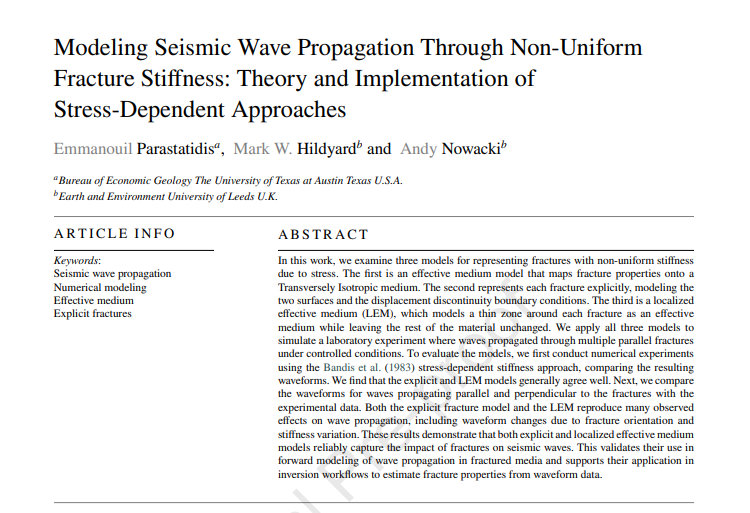

Recipe R-CS-004: Synthetic Seismic-Wave Reference Implementation merupakan prosedur pemodelan gelombang seismik sintetis menggunakan Python untuk memahami bagaimana gelombang seismik merambat dalam medium bawah permukaan dengan kecepatan konstan. Berdasarkan gambar, recipe ini menggunakan metode finite-difference atau beda hingga untuk menyelesaikan persamaan gelombang satu dimensi (1-D) dengan kondisi batas ujung tetap (fixed-end boundaries). Tujuan utamanya adalah memeriksa grid komputasi, sumber gelombang, posisi penerima (receiver), dan kestabilan numerik berdasarkan kondisi Courant–Friedrichs–Lewy (CFL) sebelum proses simulasi dijalankan. Hasil pemodelan berupa snapshot medan gelombang (wavefield snapshot) dan seismogram sintetis yang memperlihatkan perubahan perpindahan partikel terhadap posisi dan waktu. Recipe ini merupakan implementasi referensi untuk validasi numerik, bukan hasil inversi data seismik ataupun model kecepatan bawah permukaan yang diperoleh dari pengukuran lapangan.

Bilangan CFL = 0.250


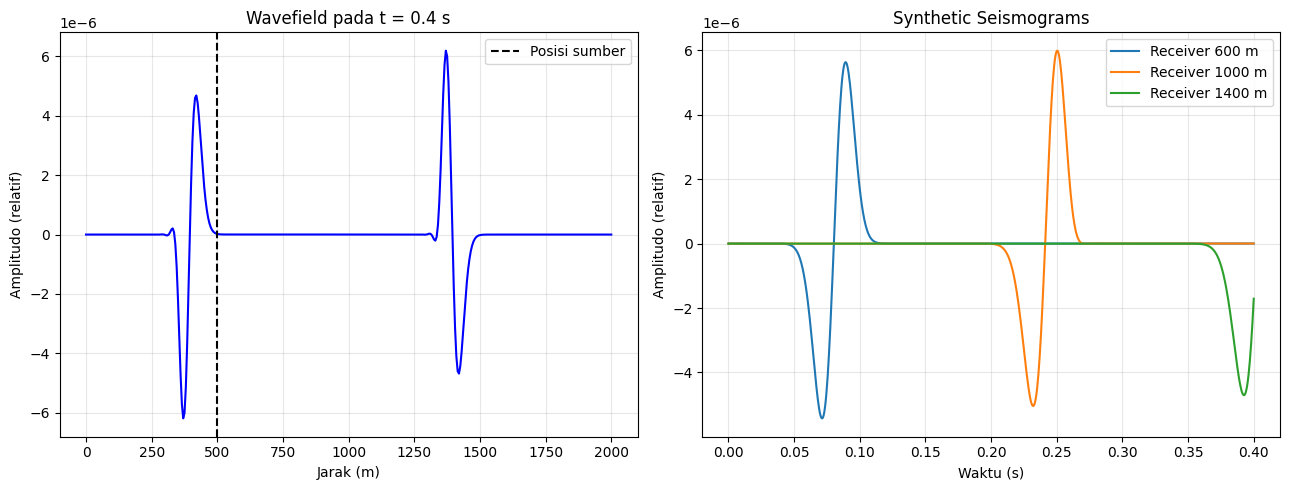

Jumlah grid ruang : 401
Jumlah langkah waktu: 801
Kecepatan gelombang: 2500 m/s
Frekuensi sumber: 25.0 Hz
Simulasi selesai.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# 1. KONFIGURASI MODEL
# ==================================================
L = 2000.0          # Panjang domain (m)
dx = 5.0            # Jarak antar-grid (m)
c = 2500.0          # Kecepatan gelombang (m/s)
T = 0.40            # Lama simulasi (s)

dt = 0.0005         # Interval waktu (s)
r = c * dt / dx     # Bilangan Courant (CFL)

# Pemeriksaan kestabilan numerik
print(f"Bilangan CFL = {r:.3f}")

if r > 1.0:
    raise ValueError("Simulasi tidak stabil: CFL harus <= 1.")

x = np.arange(0, L + dx, dx)
nt = int(round(T / dt)) + 1
time = np.arange(nt) * dt
nx = len(x)

# ==================================================
# 2. SUMBER GELOMBANG RICKER
# ==================================================
f0 = 25.0           # Frekuensi dominan (Hz)
t0 = 1.0 / f0       # Waktu pusat sumber (s)

source_x = 500.0
isrc = int(round(source_x / dx))

tau = time - t0
source = (1.0 - 2.0 * (np.pi * f0 * tau)**2) * \
         np.exp(-(np.pi * f0 * tau)**2)

# ==================================================
# 3. POSISI RECEIVER
# ==================================================
receiver_positions = [600.0, 1000.0, 1400.0]
receiver_indices = [
    int(round(pos / dx)) for pos in receiver_positions
]

seismograms = np.zeros((len(receiver_positions), nt))

# ==================================================
# 4. SOLVER BEDA HINGGA
# ==================================================
u_prev = np.zeros(nx)
u_curr = np.zeros(nx)
u_next = np.zeros(nx)

wavefield_snapshot = None
snapshot_time = 0.40
snapshot_index = int(round(snapshot_time / dt))

for n in range(nt):

    # Rekam amplitudo pada setiap receiver
    for j, ir in enumerate(receiver_indices):
        seismograms[j, n] = u_curr[ir]

    # Simpan wavefield pada waktu yang ditentukan
    if n == snapshot_index:
        wavefield_snapshot = u_curr.copy()

    # Hitung langkah waktu berikutnya
    if n == nt - 1:
        break

    u_next[1:-1] = (
        2.0 * u_curr[1:-1]
        - u_prev[1:-1]
        + r**2 * (
            u_curr[2:] - 2.0 * u_curr[1:-1]
            + u_curr[:-2]
        )
    )

    # Tambahkan sumber gelombang
    u_next[isrc] += dt**2 * source[n]

    # Kondisi batas ujung tetap
    u_next[0] = 0.0
    u_next[-1] = 0.0

    # Geser solusi antarwaktu
    u_prev, u_curr, u_next = u_curr, u_next, u_prev

# ==================================================
# 5. VISUALISASI HASIL
# ==================================================
if wavefield_snapshot is None:
    raise RuntimeError("Snapshot wavefield tidak berhasil disimpan.")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik medan gelombang pada t = 0.4 s
axes[0].plot(x, wavefield_snapshot, color="blue")
axes[0].axvline(
    source_x, color="black", linestyle="--",
    label="Posisi sumber"
)
axes[0].set_title("Wavefield pada t = 0.4 s")
axes[0].set_xlabel("Jarak (m)")
axes[0].set_ylabel("Amplitudo (relatif)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Grafik seismogram sintetis
for j, pos in enumerate(receiver_positions):
    axes[1].plot(
        time, seismograms[j],
        label=f"Receiver {pos:.0f} m"
    )

axes[1].set_title("Synthetic Seismograms")
axes[1].set_xlabel("Waktu (s)")
axes[1].set_ylabel("Amplitudo (relatif)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

# ==================================================
# 6. INFORMASI HASIL SIMULASI
# ==================================================
print(f"Jumlah grid ruang : {nx}")
print(f"Jumlah langkah waktu: {nt}")
print(f"Kecepatan gelombang: {c:.0f} m/s")
print(f"Frekuensi sumber: {f0:.1f} Hz")
print("Simulasi selesai.")


**Analisis Hasil**

Secara keseluruhan, hasil analisis menunjukkan bahwa pemodelan gelombang seismik sintetis dapat digunakan untuk mempelajari hubungan antara jarak, waktu tempuh, dan respons gelombang dalam medium homogen. Perbedaan waktu kedatangan pada setiap receiver memberikan gambaran mengenai perambatan gelombang, sedangkan bentuk dan amplitudo sinyal menunjukkan respons numerik terhadap sumber yang diberikan. Kesesuaian antara pola medan gelombang dan seismogram dapat menjadi pemeriksaan awal terhadap implementasi solver. Namun, keberhasilan simulasi belum otomatis membuktikan bahwa seluruh hasil numerik akurat; pengujian tambahan, seperti perbandingan dengan solusi analitik dan pengujian konvergensi grid, tetap diperlukan.